In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
    confusion_matrix
)
from imblearn.over_sampling import RandomOverSampler

In [2]:
columns = [
    'Id', 'RI', 'Na', 'Mg', 'Al', 'Si',
    'K', 'Ca', 'Ba', 'Fe', 'Type'
]

df = pd.read_csv('glass.data', header=None, names=columns)
df.head()

,Id,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,2,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,3,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,4,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,5,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Id      214 non-null    int64  
 1   RI      214 non-null    float64
 2   Na      214 non-null    float64
 3   Mg      214 non-null    float64
 4   Al      214 non-null    float64
 5   Si      214 non-null    float64
 6   K       214 non-null    float64
 7   Ca      214 non-null    float64
 8   Ba      214 non-null    float64
 9   Fe      214 non-null    float64
 10  Type    214 non-null    int64  
dtypes: float64(9), int64(2)
memory usage: 18.5 KB


In [4]:
df.isna().sum()

Id      0
RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

In [5]:
# Проверяем количество объектов каждого класса
df['Type'].value_counts().sort_index()

Type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64

In [6]:
# Проверяем совпадения признаков и класса без идентификатора
df.drop(columns='Id').duplicated().sum()

np.int64(1)

In [7]:
# Показываем все строки, совпадающие без учёта Id
# Запись id 39 и 40 совпадают полностью
duplicate_mask = df.drop(columns='Id').duplicated(keep=False)
df[duplicate_mask]

,Id,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
38,39,1.52213,14.21,3.82,0.47,71.77,0.11,9.57,0.0,0.0,1
39,40,1.52213,14.21,3.82,0.47,71.77,0.11,9.57,0.0,0.0,1


In [8]:
# Удаляем повторные записи без учёта идентификатора, сохраняя первую
df = df.drop_duplicates(subset=df.columns.drop('Id')).copy()
df.shape

(213, 11)

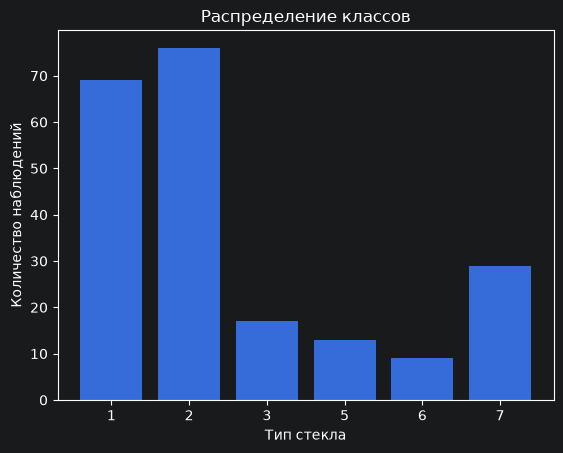

In [9]:
# Визуализируем дисбаланс классов после удаления повтора
class_counts = df['Type'].value_counts().sort_index()

plt.bar(class_counts.index.astype(str), class_counts.values)
plt.xlabel('Тип стекла')
plt.ylabel('Количество наблюдений')
plt.title('Распределение классов')
plt.show()

In [10]:
# Изучаем диапазоны и распределение числовых признаков
df.drop(columns=['Id', 'Type']).describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
count,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000
mean,1.518348,13.404085,2.679202,1.449484,72.655070,0.498873,8.954085,0.175869,0.057277
std,0.003033,0.816662,1.443691,0.495925,0.773998,0.653185,1.425882,0.498245,0.097589
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000
25%,1.516520,12.900000,2.090000,1.190000,72.280000,0.130000,8.240000,0.000000,0.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.560000,8.600000,0.000000,0.000000
75%,1.519150,13.810000,3.600000,1.630000,73.090000,0.610000,9.150000,0.000000,0.100000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000


In [11]:
# Делим датасет, 60/20/20, исключая идентификатор и отделяем целевой класс
x = df.drop(columns=['Id', 'Type'])
y = df['Type']

x_train_val, x_test, y_train_val, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

x_train, x_val, y_train, y_val = train_test_split(
    x_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print(x_train.shape, x_val.shape, x_test.shape)

(127, 9) (43, 9) (43, 9)


In [12]:
# Проверяем представленность классов в тренировочной выборке
y_train.value_counts().sort_index()

Type
1    41
2    46
3    10
5     8
6     5
7    17
Name: count, dtype: int64

In [13]:
# Создаём суммарные признаки состава стекла
x_train['Na_K_sum'] = x_train['Na'] + x_train['K']
x_train['Ca_Mg_sum'] = x_train['Ca'] + x_train['Mg']

x_val['Na_K_sum'] = x_val['Na'] + x_val['K']
x_val['Ca_Mg_sum'] = x_val['Ca'] + x_val['Mg']

x_test['Na_K_sum'] = x_test['Na'] + x_test['K']
x_test['Ca_Mg_sum'] = x_test['Ca'] + x_test['Mg']

In [14]:
# Масштабируем фичи, обучаем только на train
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled = scaler.transform(x_val)
x_test_scaled = scaler.transform(x_test)

In [15]:
# Обучаем базовый случайный лес без балансировки классов
baseline_model = RandomForestClassifier(random_state=42)
baseline_model.fit(x_train_scaled, y_train)

baseline_val_pred = baseline_model.predict(x_val_scaled)

# Accuracy
baseline_accuracy = accuracy_score(y_val, baseline_val_pred)

# F1 macro
baseline_f1 = f1_score(y_val, baseline_val_pred, average='macro')

print(baseline_accuracy, baseline_f1)

0.7906976744186046 0.7606060606060606


In [16]:
# Оцениваем качество базовой модели отдельно по классам
# класс 3 нашла только 1 обьект из 4, класс 5 найден 1 из 2
# класс 6 полностью в валидации 2 обьекта
print(classification_report(y_val, baseline_val_pred, zero_division=0))

              precision    recall  f1-score   support

           1       0.68      0.93      0.79        14
           2       0.80      0.80      0.80        15
           3       1.00      0.25      0.40         4
           5       1.00      0.50      0.67         2
           6       1.00      1.00      1.00         2
           7       1.00      0.83      0.91         6

    accuracy                           0.79        43
   macro avg       0.91      0.72      0.76        43
weighted avg       0.83      0.79      0.78        43



In [17]:
# Обучаем тот же случайный лес с балансировкой весов классов
weighted_model = RandomForestClassifier(
    random_state=42,
    class_weight='balanced'
)
weighted_model.fit(x_train_scaled, y_train)
weighted_val_pred = weighted_model.predict(x_val_scaled)

# Accuracy
weighted_accuracy = accuracy_score(y_val, weighted_val_pred)

# F1 macro
weighted_f1 = f1_score(y_val, weighted_val_pred, average='macro')

print(weighted_accuracy, weighted_f1)

0.7209302325581395 0.7352453102453103


In [18]:
# Оцениваем качество модели с балансировкой
print(classification_report(y_val, weighted_val_pred, zero_division=0))

              precision    recall  f1-score   support

           1       0.62      0.71      0.67        14
           2       0.85      0.73      0.79        15
           3       0.25      0.25      0.25         4
           5       1.00      1.00      1.00         2
           6       0.67      1.00      0.80         2
           7       1.00      0.83      0.91         6

    accuracy                           0.72        43
   macro avg       0.73      0.76      0.74        43
weighted avg       0.74      0.72      0.72        43



In [19]:
# Выравниваем количество примеров классов только в train
ros = RandomOverSampler(random_state=42)
x_train_ros, y_train_ros = ros.fit_resample(x_train_scaled, y_train)

print(pd.Series(y_train_ros).value_counts().sort_index())

Type
1    46
2    46
3    46
5    46
6    46
7    46
Name: count, dtype: int64


In [20]:
# Обучаем случайный лес на данных после oversampling
ros_model = RandomForestClassifier(random_state=42)
ros_model.fit(x_train_ros, y_train_ros)

ros_val_pred = ros_model.predict(x_val_scaled)

# Accuracy
ros_accuracy = accuracy_score(y_val, ros_val_pred)

# F1 macro
ros_f1 = f1_score(y_val, ros_val_pred, average='macro')

print(ros_accuracy, ros_f1)

0.7441860465116279 0.7724941292794463


In [21]:
# Оцениваем качество модели после oversampling
print(classification_report(y_val, ros_val_pred, zero_division=0))

              precision    recall  f1-score   support

           1       0.65      0.79      0.71        14
           2       0.79      0.73      0.76        15
           3       0.50      0.25      0.33         4
           5       1.00      1.00      1.00         2
           6       1.00      1.00      1.00         2
           7       0.83      0.83      0.83         6

    accuracy                           0.74        43
   macro avg       0.79      0.77      0.77        43
weighted avg       0.74      0.74      0.74        43



In [22]:
# Подбор гиперпараметров
depth_values = [None, 3, 5, 10]
leaf_values = [1, 2, 4]
results = []

for depth in depth_values:
    for leaf in leaf_values:
        model = RandomForestClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=42
        )
        model.fit(x_train_scaled, y_train)

        plain_val_pred = model.predict(x_val_scaled)

        # F1 macro plain
        plain_f1 = f1_score(y_val, plain_val_pred, average='macro')

        ros_candidate = RandomForestClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=42
        )
        ros_candidate.fit(x_train_ros, y_train_ros)

        ros_val_pred = ros_candidate.predict(x_val_scaled)

        # F1 macro ros
        ros_f1 = f1_score(y_val, ros_val_pred, average='macro')

        results.append({'depth': depth, 'leaf': leaf, 'plain_f1': plain_f1, 'ros_f1': ros_f1})

results_df = pd.DataFrame(results)
results_df

,depth,leaf,plain_f1,ros_f1
0,NaN,1,0.760606,0.772494
1,NaN,2,0.809848,0.743774
2,NaN,4,0.525494,0.722953
3,3.0,1,0.482997,0.713566
4,3.0,2,0.493963,0.713566
5,3.0,4,0.380923,0.713566
6,5.0,1,0.749847,0.708020
7,5.0,2,0.749847,0.718975
8,5.0,4,0.495731,0.678961
9,10.0,1,0.749992,0.772494


In [23]:
# Находим лучшие параметры отдельно для каждого способа обучения
best_plain_index = results_df['plain_f1'].idxmax()
best_ros_index = results_df['ros_f1'].idxmax()
print(f'{results_df.loc[best_plain_index]}, {results_df.loc[best_ros_index]}')

depth            NaN
leaf        2.000000
plain_f1    0.809848
ros_f1      0.743774
Name: 1, dtype: float64, depth            NaN
leaf        1.000000
plain_f1    0.760606
ros_f1      0.772494
Name: 0, dtype: float64


In [24]:
# Восстанавливаем параметры из таблицы и обучаем выбранную модель
plain_row = results_df.loc[best_plain_index]
plain_depth = None if pd.isna(plain_row['depth']) else int(plain_row['depth'])

best_plain = RandomForestClassifier(
    max_depth=plain_depth,
    min_samples_leaf=int(plain_row['leaf']),
    random_state=42
)
best_plain.fit(x_train_scaled, y_train)

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [25]:
ros_row = results_df.loc[best_ros_index]
ros_depth = None if pd.isna(ros_row['depth']) else int(ros_row['depth'])

best_ros = RandomForestClassifier(
    max_depth=ros_depth,
    min_samples_leaf=int(ros_row['leaf']),
    random_state=42
)
best_ros.fit(x_train_ros, y_train_ros)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [26]:
# Сравниваем исходные и настроенные варианты на одном тесте
baseline_test_pred = baseline_model.predict(x_test_scaled)
weighted_test_pred = weighted_model.predict(x_test_scaled)
plain_test_pred = best_plain.predict(x_test_scaled)
ros_test_pred = best_ros.predict(x_test_scaled)

# Accuracy
baseline_accuracy_test = accuracy_score(y_test, baseline_test_pred)
weighted_accuracy_test = accuracy_score(y_test, weighted_test_pred)
plain_accuracy_test = accuracy_score(y_test, plain_test_pred)
ros_accuracy_test = accuracy_score(y_test, ros_test_pred)

# F1 macro
baseline_f1_test = f1_score(y_test, baseline_test_pred, average='macro')
weighted_f1_test = f1_score(y_test, weighted_test_pred, average='macro')
plain_f1_test = f1_score(y_test, plain_test_pred, average='macro')
ros_f1_test = f1_score(y_test, ros_test_pred, average='macro')

comparison = pd.DataFrame({
    'Model': ['Baseline', 'Weighted', 'Tuned without balancing', 'RandomOverSampler'],
    'Accuracy': [
        baseline_accuracy_test, weighted_accuracy_test,
        plain_accuracy_test, ros_accuracy_test
    ],
    'F1 macro': [
        baseline_f1_test, weighted_f1_test,
        plain_f1_test, ros_f1_test
    ]
})

comparison

,Model,Accuracy,F1 macro
0,Baseline,0.767442,0.745238
1,Weighted,0.837209,0.849756
2,Tuned without balancing,0.744186,0.690937
3,RandomOverSampler,0.837209,0.850451


In [27]:
# Сравниваем распознавание классов до и после oversampling
print('Без балансировки:')
print(classification_report(y_test, baseline_test_pred, zero_division=0))

print('После oversampling:')
print(classification_report(y_test, ros_test_pred, zero_division=0))

Без балансировки:
              precision    recall  f1-score   support

           1       0.75      0.86      0.80        14
           2       0.77      0.67      0.71        15
           3       1.00      0.67      0.80         3
           5       1.00      0.67      0.80         3
           6       0.50      0.50      0.50         2
           7       0.75      1.00      0.86         6

    accuracy                           0.77        43
   macro avg       0.79      0.73      0.75        43
weighted avg       0.78      0.77      0.76        43

После oversampling:
              precision    recall  f1-score   support

           1       0.92      0.86      0.89        14
           2       0.83      0.67      0.74        15
           3       0.60      1.00      0.75         3
           5       1.00      1.00      1.00         3
           6       0.67      1.00      0.80         2
           7       0.86      1.00      0.92         6

    accuracy                           

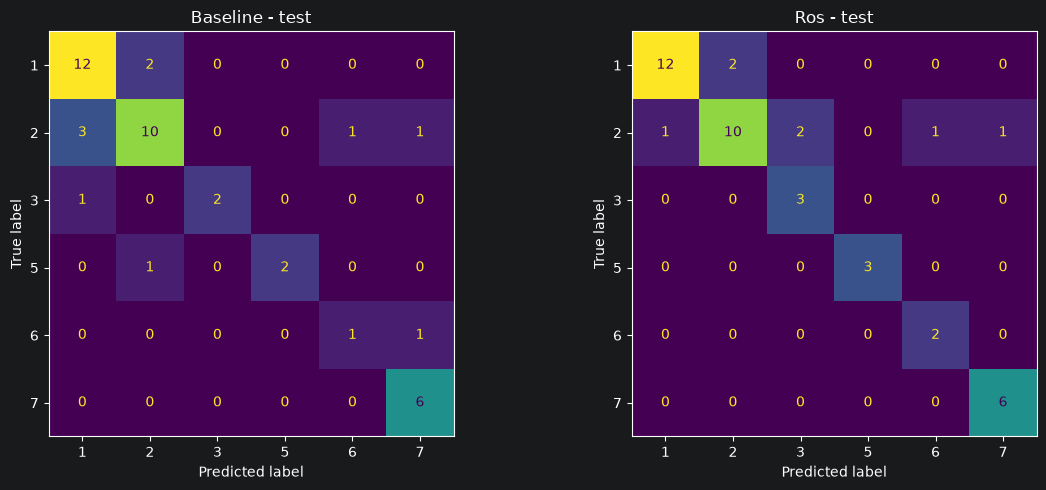

In [28]:
# Строим матрицы ошибок двух моделей на тестовой выборке
labels = [1, 2, 3, 5, 6, 7]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

disp_baseline = ConfusionMatrixDisplay(confusion_matrix(y_test, baseline_test_pred, labels=labels), display_labels=labels)
disp_baseline.plot(ax=ax[0], colorbar=False)
disp_ros = ConfusionMatrixDisplay(confusion_matrix(y_test, ros_test_pred, labels=labels), display_labels=labels)
disp_ros.plot(ax=ax[1], colorbar=False)

ax[0].set_title('Baseline - test')
ax[1].set_title('Ros - test')
plt.tight_layout()
plt.show()

На данном тестовом разбиении RandomOverSampler повысил accuracy с 0,767 до 0,837, а F1 macro - с 0,745 до 0,850 относительно модели с теми же параметрами без балансировки. Число ошибок уменьшилось с 10 до 7, улучшилась полнота классов 3, 5 и 6. На валидации эффект был неоднозначным, поэтому при небольшом размере выборок результат нельзя считать универсальным.